Exploratory notebook, investigating how GLORYS12V1 reproduce subsurface saltier waters to backtrack Smax sources.

Initially, plotting the salinity horizontal distribution over a 50-m depth layer, but then using the isopycnal reference of Silva et al. (2023), I realized that a isopycnal field would be better to investigate the saltier intrusions onto the shelf, instead looking for a single fixed geopotential layer. 

In [56]:
import warnings
warnings.filterwarnings('ignore')

In [57]:
import itertools
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import cartopy.crs as ccrs
import pandas as pd
import gsw
from glob import glob
import matplotlib.patches as patches

import matplotlib.ticker as tkr
from matplotlib.lines import Line2D
from tqdm import tqdm
from datetime import datetime

from xgcm import Grid
from xgcm.autogenerate import generate_grid_ds
import gsw

xr.set_options(keep_attrs=True)

from utils import make_map, subplots_structure, get_shelf_edge

In [58]:
# 50-m layer
ref_depth = 50
# isopycnal layer
target = np.arange(24., 25.6, 0.5) # from Silva et al (2023)

zoomed_extent= [-48, -34, -30, -16] # [-45, -39, -27, -22]

period = ['2022-02-04', '2022-03-27']
datadir = '../data/glorys'

flist = sorted(glob(f"{datadir}/smax_*.nc"))
len(flist)

5

In [59]:
dsall = xr.open_mfdataset(flist)

# cutting a very specific period after an analysis using the entire period
dsall = dsall.sel(time=slice(period[0], period[1]))

dsall.dims

Frozen({'depth': 23, 'latitude': 229, 'longitude': 265, 'time': 52})

In [60]:
bathy = xr.open_dataset('../data/gebco_updated.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

# 50-m maps

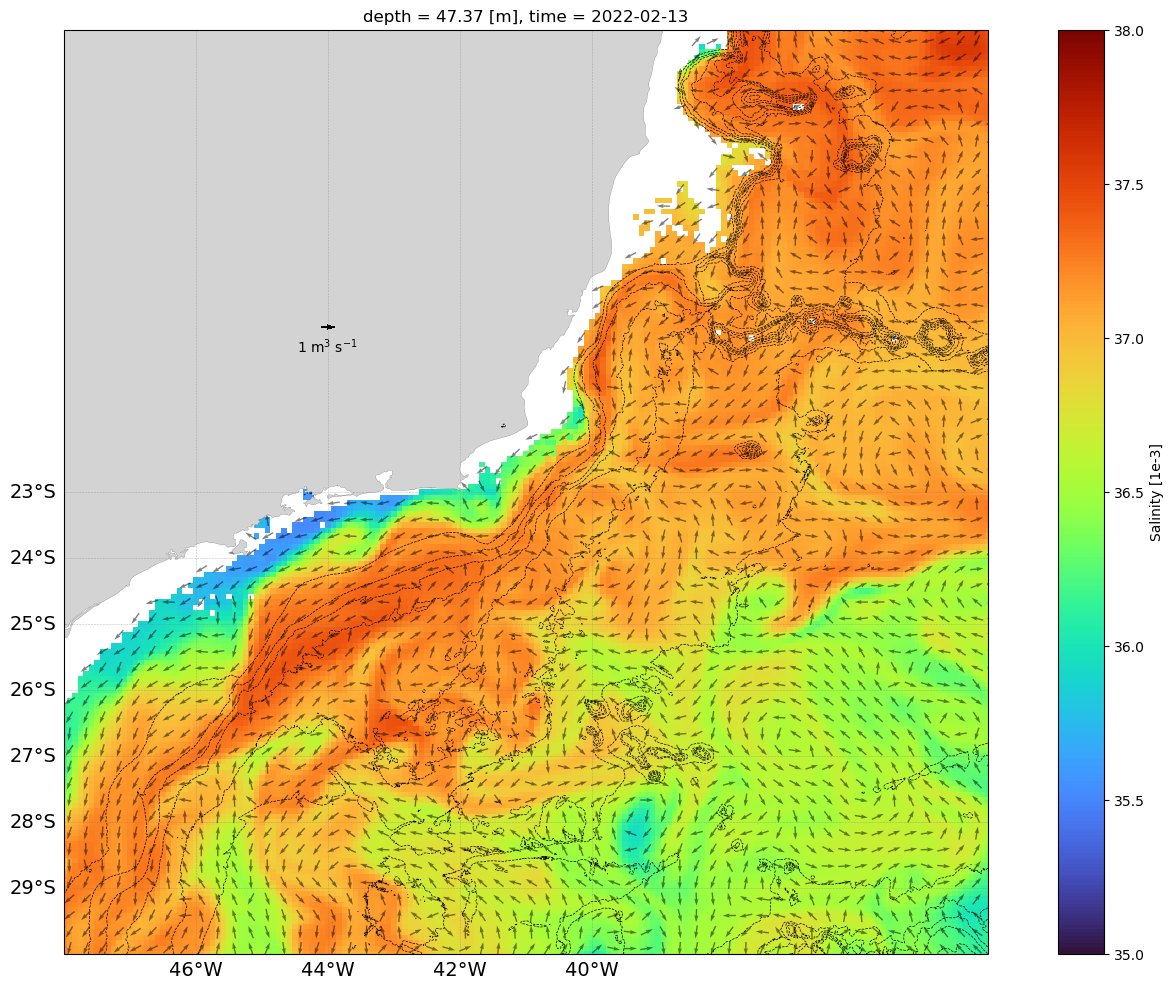

In [111]:
itime = 9
ds = dsall.isel(time=itime)
ds2 = ds.coarsen(longitude=3, latitude=3, boundary='pad').mean()
spd = np.sqrt(ds2['uo']**2 + ds2['vo']**2)
ds2['uo'] = ds2['uo'] / spd
ds2['vo'] = ds2['vo'] / spd
idz = np.argmin(np.abs(ds.depth.values - ref_depth))

fig,axes = subplots_structure(1, 1, (18,12), 1)
ax = axes[0]
ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
ax.set_extent(zoomed_extent)

cr = bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                         colors=('k'), linewidths=(0.5), linestyles=('--'))

ds.so.isel(depth=idz).squeeze().plot.pcolormesh(ax=ax, cmap='turbo', vmin=35, vmax=38)


# PLOTTING EKMAN TRANSPORT
quiver_kwargs = dict(scale=5, width=.0015, color='k', alpha=.5, angles='xy', scale_units='xy', add_guide=False)
quiverkey=[-44., -20.5, 1, r'1 m$^3$ s$^{-1}$']
quiverkey_kws=dict(labelpos='S', color='k', coordinates='data')


_ = ds2.isel(depth=idz).squeeze().plot.quiver(ax=ax, 
                    x='longitude', y='latitude', 
                    u='uo', v='vo', 
                    **quiver_kwargs)

qk = ax.quiverkey(_,
                  quiverkey[0], # x position
                  quiverkey[1], # y position
                  quiverkey[2], # unit 
                  quiverkey[3], # label
                  **quiverkey_kws).set_zorder(11)

1it [00:00,  1.46it/s]


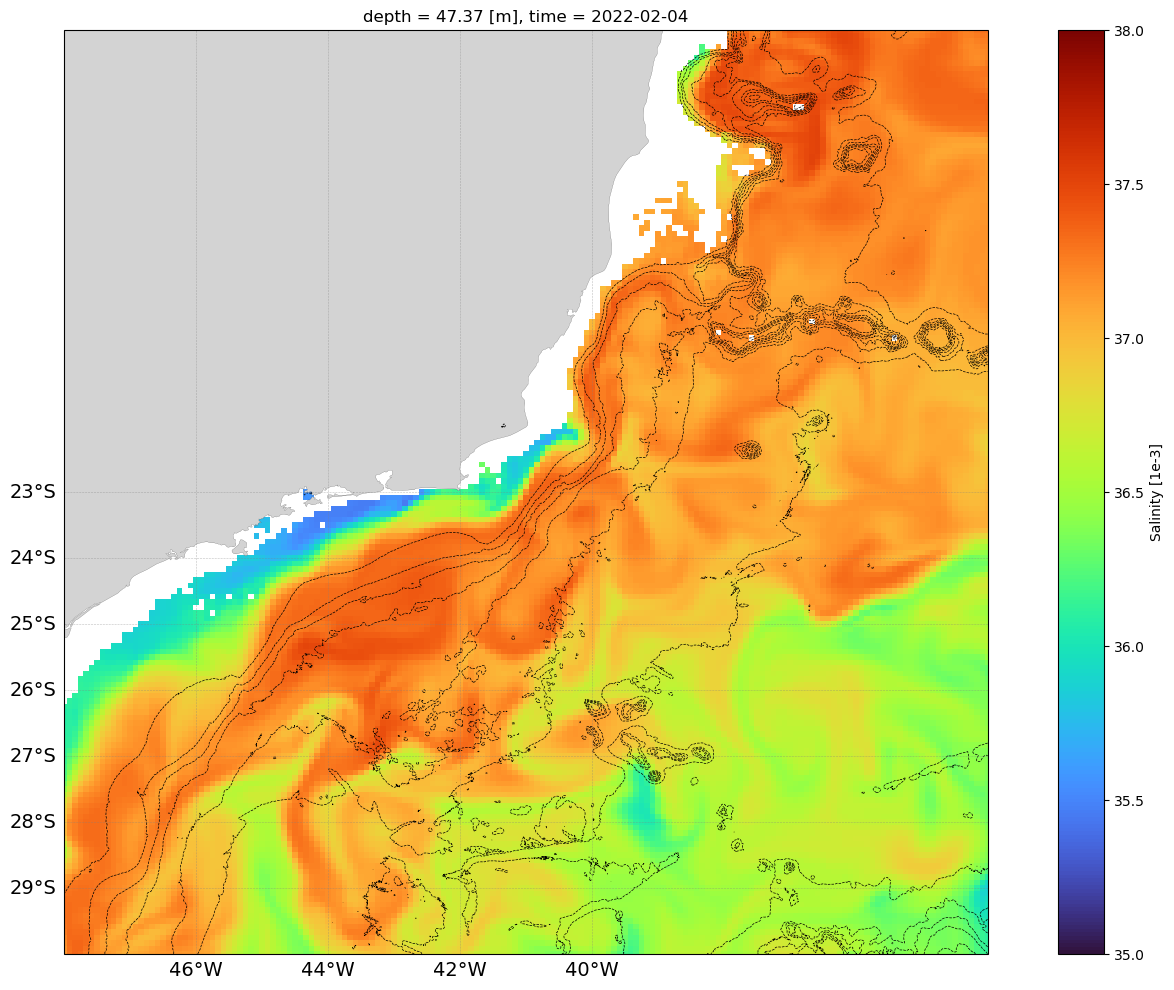

In [19]:
plotHowMany = 1
for _,itime in tqdm(enumerate(range(dsall.dims['time'])[:plotHowMany])):
    ds = dsall.isel(time=itime)

    idz = np.argmin(np.abs(ds.depth.values - ref_depth))

    fig,axes = subplots_structure(1, 1, (18,12), 1)
    ax = axes[0]
    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
    ax.set_extent(zoomed_extent)

    cr = bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                             colors=('k'), linewidths=(0.5), linestyles=('--'))
    
    ds.so.isel(depth=idz).squeeze().plot.pcolormesh(ax=ax, cmap='turbo', vmin=35, vmax=38)

    if plotHowMany != 1:
        plt.savefig(f"../figures/review_round1/glorys_50m/glorys_{ref_depth}_{pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d')}.png",
                   dpi=150,
                   bbox_inches='tight')
        plt.close('all')

# 25-26 isopycnals maps

To run this section, need to change kernel to JUPYTER

In [20]:
def prepare_isopycnal_surfaces(ds, target):
    ds['sigma_0'] = gsw.sigma0(ds['so'], ds['thetao'])
    
    # Generate 'full' dataset, which includes additional coordinate `depth_left` and appropriate attributes.
    ds_full = generate_grid_ds(ds, {'Z':'depth'})
    
    # Create grid object
    grid = Grid(ds_full, periodic=False)
    
    target_values = levels=np.arange(24., 25.6, 0.5)
    
    so_sigma = grid.transform(
      ds_full.so,
      'Z',
      target_values,
      target_data=ds_full.sigma_0
    )
    
    ds_sigma = xr.Dataset({'so': so_sigma})
    
    return ds_sigma

1it [00:00,  1.39it/s]


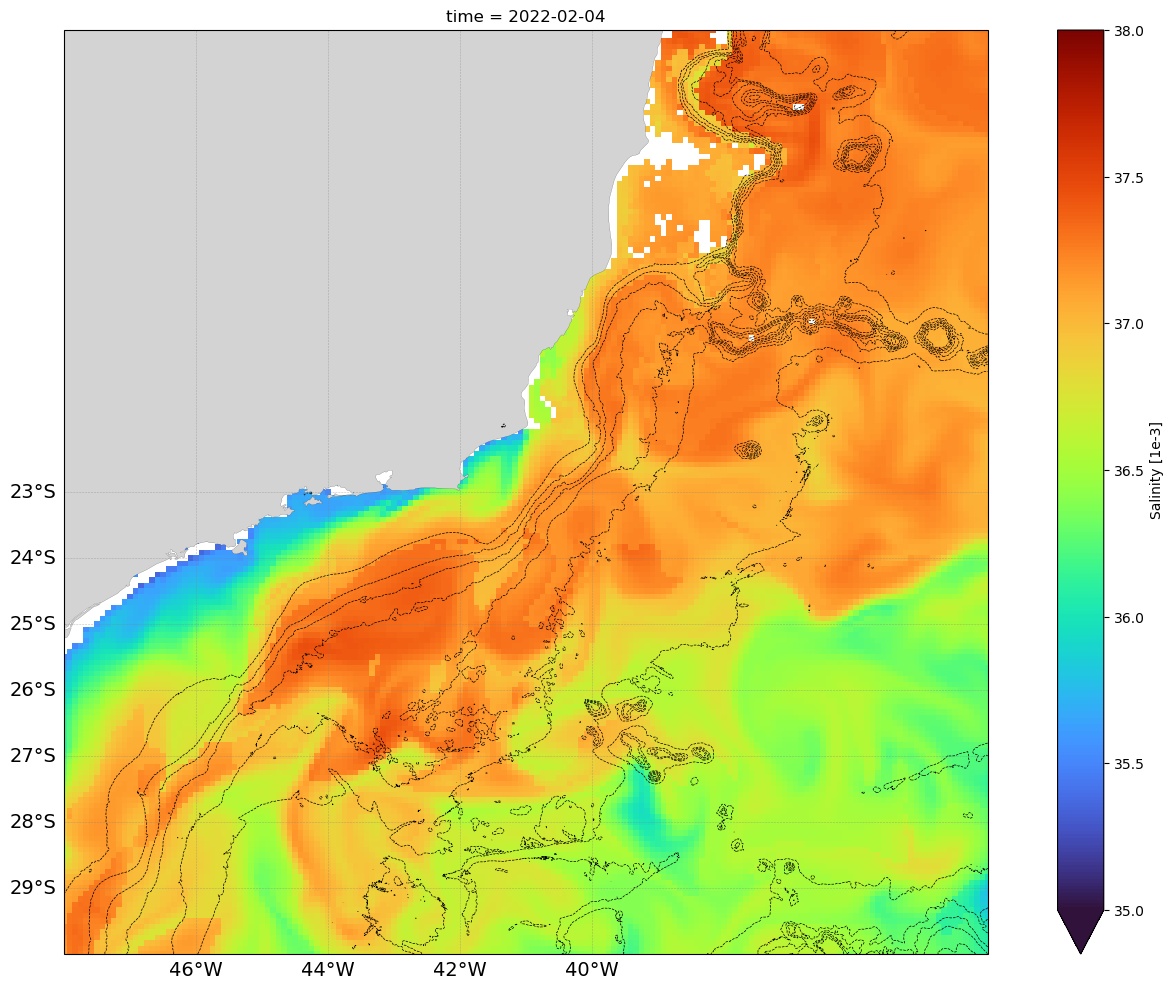

In [29]:
plotHowMany = 1

for _,itime in tqdm(enumerate(range(dsall.dims['time'])[:plotHowMany])):
    ds = dsall.isel(time=itime)
    
    ds_sigma = prepare_isopycnal_surfaces(ds, target)
    
    dsplot = ds_sigma.mean(dim='sigma_0')
    
    fig,axes = subplots_structure(1, 1, (18,12), 1)
    ax = axes[0]
    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
    ax.set_extent(zoomed_extent)

    # ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
    cr = bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                             colors=('k'), linewidths=(0.5), linestyles=('--'))
    
    dsplot.so.plot.pcolormesh(ax=ax, x='longitude', y='latitude', cmap='turbo', vmin=35, vmax=38)

    if plotHowMany != 1:
        # plt.savefig(f"../figures/review_round1/glorys_isopycnal/glorys_isopycnal_{pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d')}.png",
        #            dpi=150,
        #            bbox_inches='tight')
        plt.close('all')

## Exploring TS plot on the possible Smax source

In [52]:
bbox_area = [-39.5, -38.5, -20.5, -20]
bbox = {'longitude': slice(-39.5, -38.5),
        'latitude': slice(-20.5, -19.5)}
dsplot = dsall.sel(**bbox).isel(time=0)

dsplot = dsall.sel(longitude=-39, latitude=-20, method='nearest')

In [35]:
def parametric_isopycnal():
    
    T = np.linspace(10, 30, 50)
    S = np.linspace(34, 38, 50)
    T,S = np.meshgrid(T,S)
    
    rho = gsw.sigma0(S, T) # + 1000
        
    return S,T,rho

def build_fig_structure(xlim, ylim):
    S,T,rho = parametric_isopycnal()
    
    fig,ax = plt.subplots(figsize=(10,10))
    cs = ax.contour(S, T, rho, colors='grey', zorder=1, linestyles='--', linewidths=0.5)
    cl=plt.clabel(cs, fontsize=10, inline=True, fmt='%.1f')
    ax.set(
        xlim=xlim,
        ylim=ylim,
        xlabel='absolute salinity [g/kg]',
        ylabel='temperature [oC]'
    )
    
    return fig,ax

In [53]:
salt = dsplot.so.values
temp = dsplot.thetao.values

import gsw
dens = gsw.sigma0(salt, temp)

cond1 = dens > 24.6
cond2 = dens < 25.6
cond3 = salt > 37

# Índices onde TODAS as condições são verdadeiras
indices = np.where(cond1 & cond2 & cond3)[0]

In [54]:
indices = np.unique(indices)

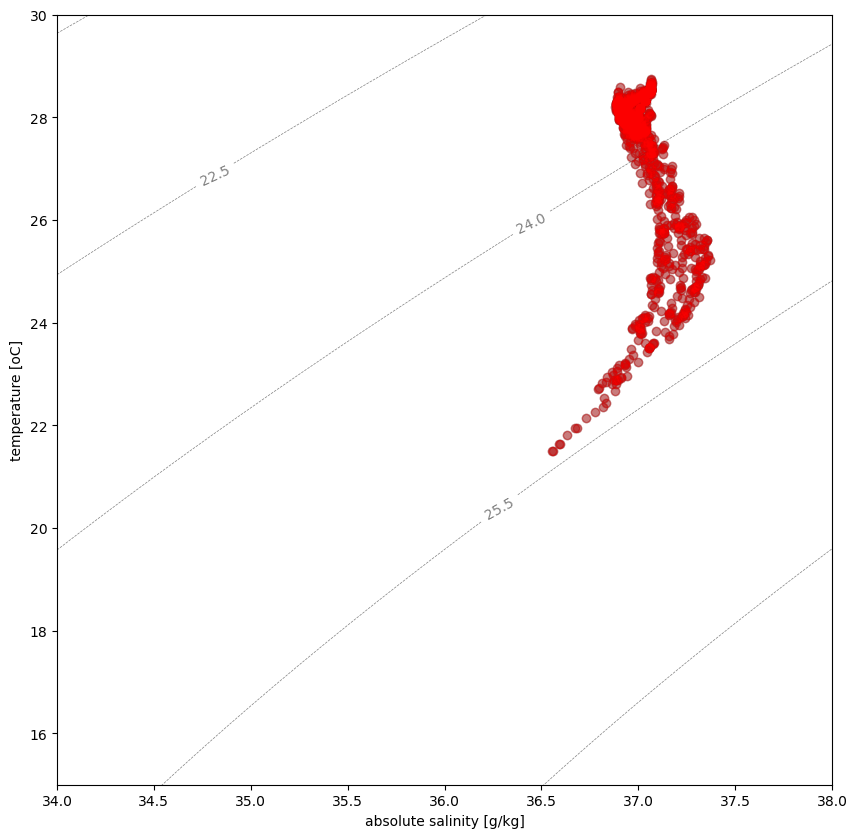

In [55]:
import numpy as np

fig,ax = build_fig_structure(xlim=[34, 38], ylim=[15,30])
ax.scatter(salt, temp, c='k', alpha=.3)

ax.scatter(salt[indices], temp[indices], c='r', alpha=.3)